# Movie Review Classification System

In [5]:
from wordcloud import WordCloud
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
import math

# Firstly we need to install and import our libraries. 

wordcloud: Used to generate word clouds from text data. Word clouds are a way to visually represent the frequency of words in a text, where more frequently occurring words appear larger.

os: Used for file and directory operations. This library helps with tasks such as managing file paths, creating new folders, or reading/writing files.

pandas: A powerful library for data analysis and manipulation. It allows you to load, filter, group, and analyze tabular data in DataFrames.

numpy: A library for numerical computing. It provides support for large, multi-dimensional arrays and matrices, along with a collection of mathematical functions to operate on these arrays.

matplotlib.pyplot: A library for data visualization. It enables the creation of plots, line charts, histograms, and other types of graphs. 

seaborn: A data visualization library built on top of matplotlib. It provides a higher-level interface for drawing statistical graphics and is often used for its more visually appealing charts. Useful for visualizing patterns and correlations in data.

re: The regular expressions library. It is used for pattern matching and text processing.

collections.defaultdict: Part of Python’s collections module. It’s a dictionary-like data structure with a default value for nonexistent keys. Often used to store word frequencies or class-based counts, especially in algorithms like Naive Bayes.

concurrent.futures.ThreadPoolExecutor: A library for parallel processing in Python. It allows you to run multiple threads at the same time, enabling multithreading. This is helpful for speeding up long-running tasks by running them in parallel.

### pullData Function: 
The pullData function reads all .txt files in a specified directory, extracts the review text and rating (assumed to be part of the filename), and returns a DataFrame with two columns: review and rating. This makes it easier to analyze or process the data in a structured format.

In [7]:
def pullData(directoryPath):
    data = []
    
    for filename in os.listdir(directoryPath):
        if filename.endswith('.txt'):
            file_path = os.path.join(directoryPath, filename)

            rating = int(filename.split('_')[1].split('.')[0])
    
            with open(file_path, 'r', encoding='utf-8') as file:
                review = file.read().strip()
    
            data.append({'review': review, 'rating': rating})
    
    df = pd.DataFrame(data)
    return df

In [11]:
trainPos = pullData("aclImdb/train/pos")
trainNeg = pullData("aclImdb/train/neg")
testPos = pullData("aclImdb/test/pos")
testNeg = pullData("aclImdb/test/neg")

### We are concatenating our positive and negative datasets because we will use them together for training and testing.

In [13]:
train = pd.concat([trainPos, trainNeg], axis=0, ignore_index=True)

In [15]:
test = pd.concat([testPos,testNeg],axis= 0 , ignore_index = True)

### We are labeling our data as positive or negative based on their rating. If the rating is 7 or higher, it is labeled as positive, and if the rating is 4 or lower, it is labeled as negative.

In [17]:
train.loc[train['rating'] >= 7, 'class'] = "positive"
train.loc[train['rating'] <= 4, 'class'] = "negative"
test.loc[test['rating'] >= 7, 'class'] = "positive"
test.loc[test['rating'] <= 4, 'class'] = "negative"

### ratingDist Function:

ratingDist takes the ratings and counts data to produce a bar chart , showing the frequency distribution of ratings with clear labels, title, and y-axis grid lines for readability.

In [19]:
def ratingDist(df):
    rating_counts = df['rating'].value_counts().sort_index()  

    plt.figure(figsize=(10, 6))
    
    sns.barplot(x=rating_counts.index, y=rating_counts.values, color='orange', alpha=0.8)
    
    plt.title("Rating Distribution in Dataset")
    plt.xlabel("Rating")
    plt.ylabel("Frequency")
    
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    
    plt.show()

### countOfTypes Function:

countOfTypes gives information about the distribution of positive and negative classes

In [21]:
def countOfTypes(df):
    class_counts = df['class'].value_counts()
    class_counts.plot(kind='bar')
    plt.title('Class Counts')
    plt.xlabel('Class')
    plt.ylabel('Frequency')
    plt.show()

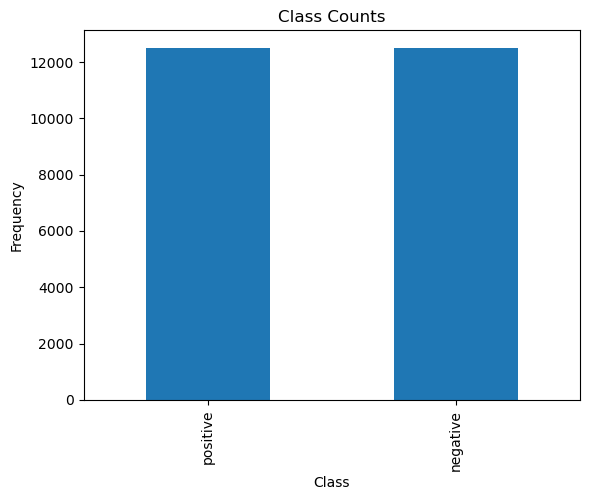

In [23]:
countOfTypes(train)

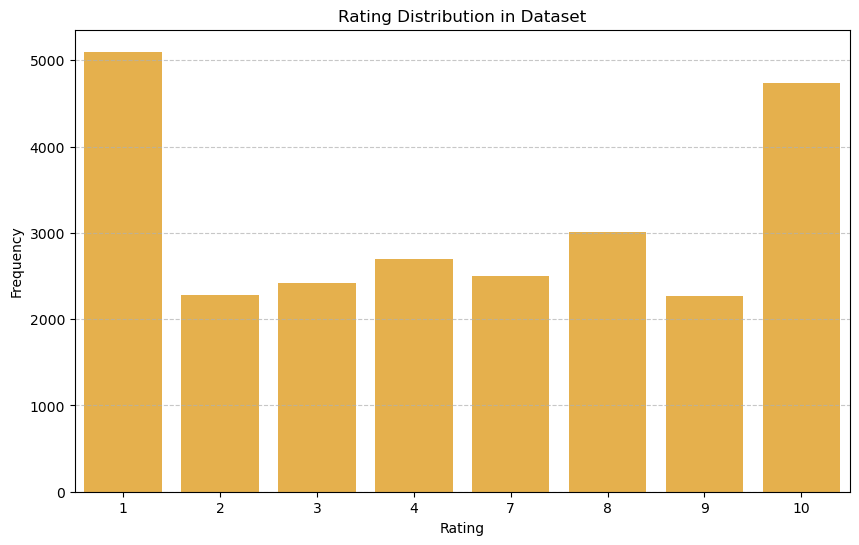

In [25]:
ratingDist(train)

### textLengthAndRating Function:

textLengthAndRating function visualizes the relationship between review length and ratings in a dataset. It calculates the length of each review and plots two bar charts to help analyze the data.

In [28]:
def textLengthAndRating(df):

    df['text_length'] = df['review'].apply(len)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(x='rating', y='text_length', data=df, color="skyblue", alpha=0.8)
    plt.title("Average Review Length by Rating")
    plt.xlabel("Rating")
    plt.ylabel("Average Review Length")
    plt.show()
    
    plt.figure(figsize=(10, 6))
    sns.barplot(x='class', y='text_length', data=df, color="orange", errorbar=None, order=['negative', 'positive'])
    plt.title("Average Review Length by Class (Positive/Negative)")
    plt.xlabel("Class")
    plt.ylabel("Average Review Length")
    plt.show()

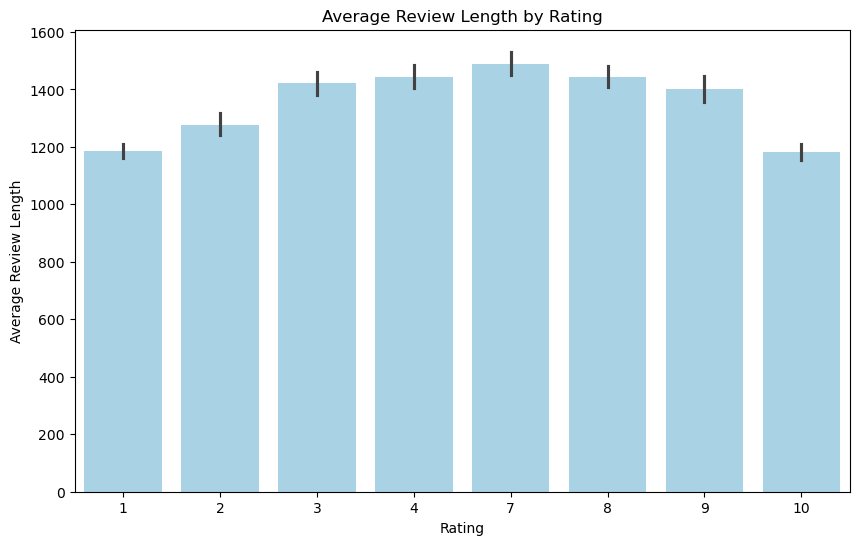

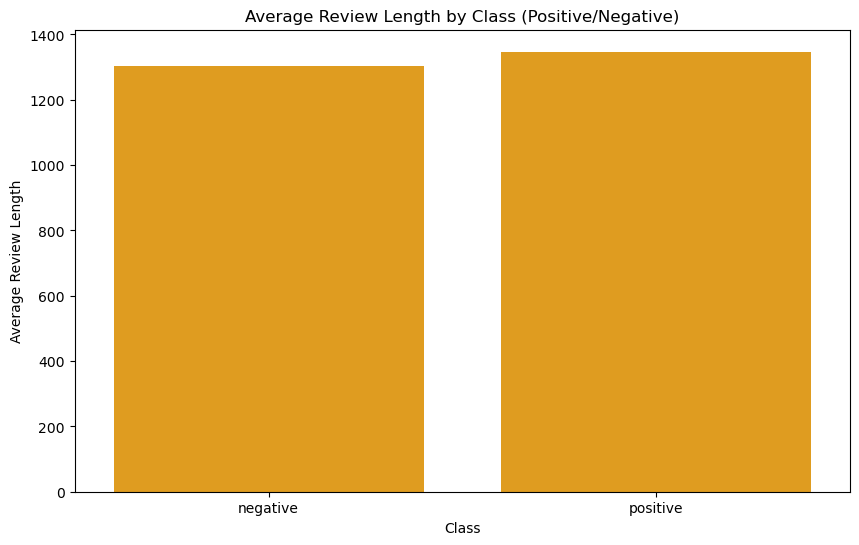

In [30]:
textLengthAndRating(train)

### usedWordsPlot function:
creates a word cloud to visualize frequently used words across all reviews in the dataset. It combines all review text into a single string, generates the word cloud.

In [33]:
def usedWordsPlot(df):
    text = " ".join(df['review']) 
    plt.figure(figsize=(10, 6))
    wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.title('Frequently Used Words in Reviews')
    plt.show()

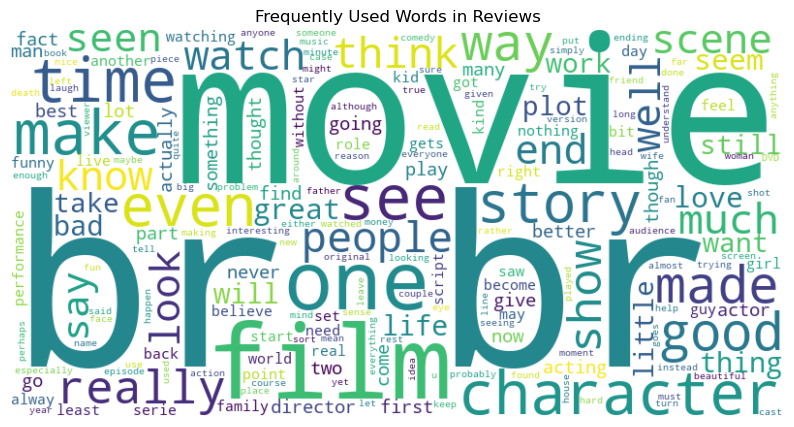

In [35]:
usedWordsPlot(train)

In [36]:
def wordList(df):
    text = " ".join(df['review'])
    
    wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)
    word_frequencies = wordcloud.words_  

    word_list = list(word_frequencies.keys())
    
    return word_list

In [37]:
wordList(train)

['br br',
 'movie',
 'film',
 'one',
 'see',
 'make',
 'time',
 'character',
 'even',
 'story',
 'good',
 'made',
 'way',
 'really',
 'show',
 'people',
 'think',
 'much',
 'watch',
 'scene',
 'know',
 'well',
 'end',
 'look',
 'seen',
 'say',
 'great',
 'seem',
 'love',
 'will',
 'life',
 'bad',
 'thing',
 'plot',
 'little',
 'work',
 'still',
 'want',
 'take',
 'acting',
 'find',
 'give',
 'actor',
 'lot',
 'first',
 'come',
 'many',
 'play',
 'something',
 'director',
 'two',
 'part',
 'now',
 'going',
 'best',
 'man',
 'fact',
 'better',
 'go',
 'though',
 'never',
 'actually',
 'thought',
 'watching',
 'funny',
 'feel',
 'role',
 'nothing',
 'back',
 'got',
 'another',
 'real',
 'world',
 'may',
 'point',
 'set',
 'kind',
 'performance',
 'guy',
 'saw',
 'girl',
 'least',
 'right',
 'script',
 'believe',
 'become',
 'serie',
 'kid',
 'alway',
 'without',
 'day',
 'family',
 'live',
 'need',
 'start',
 'bit',
 'gets',
 'interesting',
 'book',
 'course',
 'rather',
 'quite',
 'put',

#### After examining the most used word list and word cloud, I noticed many words that don’t contribute meaningfully to the review’s positivity or negativity, so we need to remove them.

#### stop_words_english.txt is a file I found online that contains common stop words for natural language processing.

file_path = 'stop_words_english.txt'

with open(file_path, 'r', encoding='utf-8') as file:
    lines = file.readlines()

stopWords = [line.strip() for line in lines]

In [39]:
stopWords = [
    "able", "about", "above", "abroad", "according", "accordingly", "across", "actually", "adj", "after",
    "afterwards", "again", "against", "ago", "ahead", "ain't", "all", "allow", "allows", "almost", "alone",
    "along", "alongside", "already", "also", "although", "always", "am", "amid", "amidst", "among",
    "amongst", "an", "and", "another", "any", "anybody", "anyhow", "anyone", "anything", "anyway",
    "anyways", "anywhere", "apart", "appear", "appreciate", "appropriate", "are", "aren't", "around", 
    "as", "a's", "aside", "ask", "asking", "associated", "at", "available", "away", "awfully", "back",
    "backward", "backwards", "be", "became", "because", "become", "becomes", "becoming", "been",
    "before", "beforehand", "begin", "behind", "being", "believe", "below", "beside", "besides", "best",
    "better", "between", "beyond", "both", "brief", "but", "by", "came", "can", "cannot", "cant", "can't",
    "caption", "cause", "causes", "certain", "certainly", "changes", "clearly", "c'mon", "co", "co.",
    "com", "come", "comes", "concerning", "consequently", "consider", "considering", "contain",
    "containing", "contains", "corresponding", "could", "couldn't", "course", "c's", "currently", "dare",
    "daren't", "definitely", "described", "despite", "did", "didn't", "different", "directly", "do",
    "does", "doesn't", "doing", "done", "don't", "down", "downwards", "during", "each", "edu", "eg",
    "eight", "eighty", "either", "else", "elsewhere", "end", "ending", "enough", "entirely", "especially",
    "et", "etc", "even", "ever", "evermore", "every", "everybody", "everyone", "everything", "everywhere",
    "ex", "exactly", "example", "except", "fairly", "far", "farther", "few", "fewer", "fifth", "first",
    "five", "followed", "following", "follows", "for", "forever", "former", "formerly", "forth", "forward",
    "found", "four", "from", "further", "furthermore", "get", "gets", "getting", "given", "gives", "go",
    "goes", "going", "gone", "got", "gotten", "greetings", "had", "hadn't", "half", "happens", "hardly",
    "has", "hasn't", "have", "haven't", "having", "he", "he'd", "he'll", "hello", "help", "hence", "her",
    "here", "hereafter", "hereby", "herein", "here's", "hereupon", "hers", "herself", "he's", "hi", "him",
    "himself", "his", "hither", "hopefully", "how", "howbeit", "however", "hundred", "i'd", "ie", "if",
    "ignored", "i'll", "i'm", "immediate", "in", "inasmuch", "inc", "inc.", "indeed", "indicate",
    "indicated", "indicates", "inner", "inside", "insofar", "instead", "into", "inward", "is", "isn't",
    "it", "it'd", "it'll", "its", "it's", "itself", "i've", "just", "k", "keep", "keeps", "kept", "know",
    "known", "knows", "last", "lately", "later", "latter", "latterly", "least", "less", "lest", "let",
    "let's", "like", "liked", "likely", "likewise", "little", "look", "looking", "looks", "low", "lower",
    "ltd", "made", "mainly", "make", "makes", "many", "may", "maybe", "mayn't", "me", "mean", "meantime",
    "meanwhile", "merely", "might", "mightn't", "mine", "minus", "miss", "more", "moreover", "most",
    "mostly", "mr", "mrs", "much", "must", "mustn't", "my", "myself", "name", "namely", "nd", "near",
    "nearly", "necessary", "need", "needn't", "needs", "neither", "never", "neverf", "neverless",
    "nevertheless", "new", "next", "nine", "ninety", "no", "nobody", "non", "none", "nonetheless",
    "noone", "no-one", "nor", "normally", "not", "nothing", "notwithstanding", "novel", "now", "nowhere",
    "obviously", "of", "off", "often", "oh", "ok", "okay", "old", "on", "once", "one", "ones", "one's",
    "only", "onto", "opposite", "or", "other", "others", "otherwise", "ought", "oughtn't", "our", "ours",
    "ourselves", "out", "outside", "over", "overall", "own", "particular", "particularly", "past", "per",
    "perhaps", "placed", "please", "plus", "possible", "presumably", "probably", "provided", "provides",
    "que", "quite", "qv", "rather", "rd", "re", "really", "reasonably", "recent", "recently", "regarding",
    "regardless", "regards", "relatively", "respectively", "right", "round", "said", "same", "saw", "say",
    "saying", "says", "second", "secondly", "see", "seeing", "seem", "seemed", "seeming", "seems", "seen",
    "self", "selves", "sensible", "sent", "serious", "seriously", "seven", "several", "shall", "shan't",
    "she", "she'd", "she'll", "she's", "should", "shouldn't", "since", "six", "so", "some", "somebody",
    "someday", "somehow", "someone", "something", "sometime", "sometimes", "somewhat", "somewhere",
    "soon", "sorry", "specified", "specify", "specifying", "still", "sub", "such", "sup", "sure", "take",
    "taken", "taking", "tell", "tends", "th", "than", "thank", "thanks", "thanx", "that", "that'll",
    "thats", "that's", "that've", "the", "their", "theirs", "them", "themselves", "then", "thence",
    "there", "thereafter", "thereby", "there'd", "therefore", "therein", "there'll", "there're", "theres",
    "there's", "thereupon", "there've", "these", "they", "they'd", "they'll", "they're", "they've",
    "thing", "things", "think", "third", "thirty", "this", "thorough", "thoroughly", "those", "though",
    "three", "through", "throughout", "thru", "thus", "till", "to", "together", "too", "took", "toward",
    "towards", "tried", "tries", "truly", "try", "trying", "t's", "twice", "two", "un", "under",
    "underneath", "undoing", "unfortunately", "unless", "unlike", "unlikely", "until", "unto", "up",
    "upon", "upwards", "us", "use", "used", "useful", "uses", "using", "usually", "v", "value", "various",
    "versus", "very", "via", "viz", "vs", "want", "wants", "was", "wasn't", "way", "we", "we'd",
    "welcome", "well",    "we'll", "went", "were", "we're", "weren't", "we've", "what", "whatever", "what'll", "what's",
    "what've", "when", "whence", "whenever", "where", "whereafter", "whereas", "whereby", "wherein",
    "where's", "whereupon", "wherever", "whether", "which", "whichever", "while", "whilst", "whither",
    "who", "who'd", "whoever", "whole", "who'll", "whom", "whomever", "who's", "whose", "why", "will",
    "willing", "wish", "with", "within", "without", "wonder", "won't", "would", "wouldn't", "yes", "yet",
    "you", "you'd", "you'll", "your", "you're", "yours", "yourself", "yourselves", "you've", "zero", "a",
    "how's", "i", "when's", "why's", "b", "c", "d", "e", "f", "g", "h", "j", "l", "m", "n", "o", "p", "q",
    "r", "s", "t", "u", "uucp", "w", "x", "y", "z", "I", "www", "amount", "bill", "bottom", "call",
    "computer", "con", "couldnt", "cry", "de", "describe", "detail", "due", "eleven", "empty", "fifteen",
    "fifty", "fill", "find", "fire", "forty", "front", "full", "give", "hasnt", "herse", "himse", "interest",
    "itse", "mill", "move", "myse", "part", "put", "show", "side", "sincere", "sixty", "system", "ten",
    "thick", "thin", "top", "twelve", "twenty", "abst", "accordance", "act", "added", "adopted", "affected",
    "affecting", "affects", "ah", "announce", "anymore", "apparently", "approximately", "aren", "arent",
    "arise", "auth", "beginning", "beginnings", "begins", "biol", "briefly", "ca", "date", "ed", "effect",
    "et-al", "ff", "fix", "gave", "giving", "heres", "hes", "hid", "home", "id", "im", "immediately",
    "importance", "important", "index", "information", "invention", "itd", "keys", "kg", "km", "largely",
    "lets", "line", "'ll", "means", "mg", "million", "ml", "mug", "na", "nay", "necessarily", "nos",
    "noted", "obtain", "obtained", "omitted", "ord", "owing", "page", "pages", "poorly", "possibly",
    "potentially", "pp", "predominantly", "present", "previously", "primarily", "promptly", "proud",
    "quickly", "ran", "readily", "ref", "refs", "related", "research", "resulted", "resulting", "results",
    "run", "sec", "section", "shed", "shes", "showed", "shown", "showns", "shows", "significant",
    "significantly", "similar", "similarly", "slightly", "somethan", "specifically", "state", "states",
    "stop", "strongly", "substantially", "successfully", "sufficiently", "suggest", "thered", "thereof",
    "therere", "thereto", "theyd", "theyre", "thou", "thoughh", "thousand", "throug", "til", "tip", "ts",
    "ups", "usefully", "usefulness", "'ve", "vol", "vols", "wed", "whats", "wheres", "whim", "whod",
    "whos", "widely", "words", "world", "youd", "youre"]

In [40]:
def preprocessTextNGram(text, n=1):
    text = re.sub(r'<.*?>|[^\w\s]', '', text.lower())
    filteredWords = [word for word in text.split() if word not in stopWords]
    
    ngrams = [" ".join(filteredWords[i:i+n]) for i in range(len(filteredWords) - n + 1)]
    return ngrams

In [43]:
oneGram = train.copy()
oneGram['review'] = oneGram['review'].apply(preprocessTextNGram)

## After our preproccess frequently used words in POSITIVE reviews

In [44]:
def afterPreproccessWordCloud(df):
    text = " ".join([" ".join(review) for review in df['review']])
    plt.figure(figsize=(10, 6))
    wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.show()

In [45]:
def afterPreproccessWordList(df):
    text = " ".join([" ".join(review) for review in df['review']])
    
    wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)
    word_frequencies = wordcloud.words_  

    word_list = list(word_frequencies.keys())
    
    return word_list

## Frequently Used Words in Reviews on POSITIVE ONEGRAM after Preprocessing'

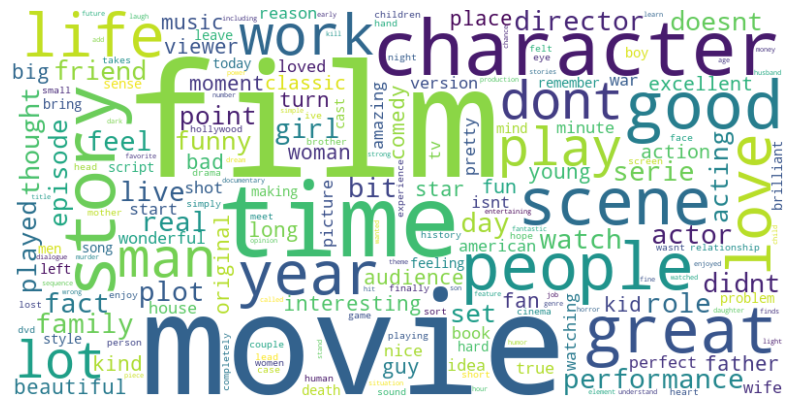

In [46]:
afterPreproccessWordCloud(oneGram[oneGram['class'] == 'positive'])

In [50]:
afterPreproccessWordList(oneGram[oneGram['class'] == 'positive'])

['film',
 'movie',
 'time',
 'character',
 'story',
 'good',
 'scene',
 'great',
 'people',
 'year',
 'life',
 'love',
 'work',
 'man',
 'play',
 'dont',
 'lot',
 'performance',
 'plot',
 'actor',
 'director',
 'role',
 'day',
 'real',
 'fact',
 'bit',
 'serie',
 'watch',
 'feel',
 'live',
 'family',
 'girl',
 'friend',
 'set',
 'didnt',
 'doesnt',
 'thought',
 'point',
 'played',
 'funny',
 'episode',
 'acting',
 'interesting',
 'moment',
 'star',
 'fan',
 'kind',
 'beautiful',
 'turn',
 'big',
 'original',
 'music',
 'place',
 'father',
 'comedy',
 'audience',
 'bad',
 'woman',
 'kid',
 'guy',
 'young',
 'viewer',
 'long',
 'excellent',
 'fun',
 'action',
 'classic',
 'wonderful',
 'perfect',
 'shot',
 'version',
 'nice',
 'start',
 'watching',
 'minute',
 'picture',
 'wife',
 'true',
 'reason',
 'war',
 'idea',
 'amazing',
 'isnt',
 'tv',
 'american',
 'pretty',
 'house',
 'loved',
 'book',
 'problem',
 'remember',
 'making',
 'men',
 'script',
 'today',
 'cast',
 'song',
 'boy',
 '

## Frequently Used Words in Reviews on NEGATIVE ONEGRAM after Preprocessing'

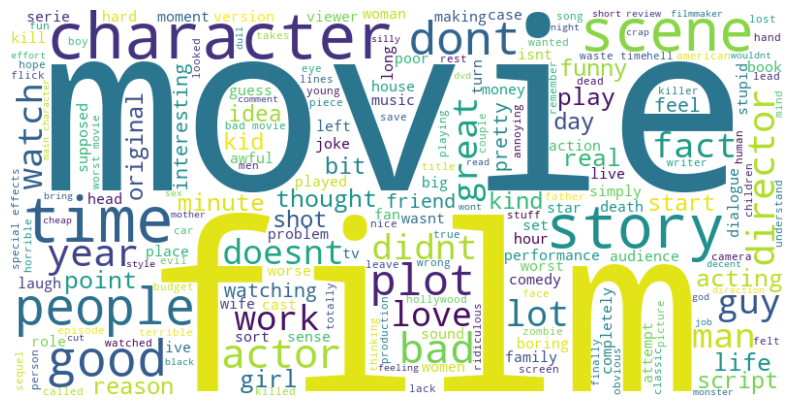

In [51]:
afterPreproccessWordCloud(oneGram[oneGram['class'] == 'negative'])

In [52]:
afterPreproccessWordList(oneGram[oneGram['class'] == 'negative'])

['movie',
 'film',
 'character',
 'time',
 'story',
 'scene',
 'people',
 'good',
 'dont',
 'plot',
 'bad',
 'actor',
 'year',
 'director',
 'lot',
 'work',
 'fact',
 'great',
 'guy',
 'didnt',
 'watch',
 'man',
 'love',
 'doesnt',
 'thought',
 'point',
 'minute',
 'girl',
 'real',
 'play',
 'life',
 'acting',
 'funny',
 'kid',
 'kind',
 'shot',
 'script',
 'start',
 'original',
 'reason',
 'bit',
 'day',
 'idea',
 'watching',
 'feel',
 'pretty',
 'friend',
 'interesting',
 'performance',
 'audience',
 'set',
 'role',
 'star',
 'turn',
 'stupid',
 'isnt',
 'woman',
 'fan',
 'long',
 'boring',
 'comedy',
 'cast',
 'place',
 'making',
 'moment',
 'family',
 'problem',
 'music',
 'big',
 'wasnt',
 'kill',
 'simply',
 'supposed',
 'live',
 'left',
 'book',
 'hard',
 'ive',
 'sort',
 'action',
 'serie',
 'dialogue',
 'sense',
 'version',
 'joke',
 'hour',
 'played',
 'poor',
 'attempt',
 'laugh',
 'sound',
 'house',
 'worst',
 'completely',
 'money',
 'worse',
 'head',
 'awful',
 'viewer',


###  NaiveBayesClassifierNgram class:

NaiveBayesClassifierNgram class implements a Naive Bayes classifier with support for n-grams. It processes text data, calculates word frequencies per class, and uses these frequencies to predict class labels for new text data

ThreadPoolExecutor allows tasks to run in parallel, improving performance by reducing total execution time. Without it, tasks run sequentially, leading to noticeable slowdowns, especially with large data or multiple tasks.

In [53]:
class NaiveBayesClassifierOptimizedNgram:
    def __init__(self, n=1):
        self.classes = None
        self.vocab = set()
        self.wordCounts = {}
        self.classCounts = {}
        self.totalDocs = 0
        self.n = n

    def getWordCounts(self):
        return self.wordCounts

    def getVocab(self):
        return self.vocab

    def getWordCounts(self):
        return self.wordCounts

    def getClassCounts(self):
        return self.classCounts

    def gettotalDocs(self):
        return self.totalDocs

    def preprocessText(self, text):
        text = re.sub(r'<.*?>|[^\w\s]', '', text.lower())
        words = [word for word in text.split() if word not in stopWords]

        if self.n == 1:
            return words
        ngrams = zip(*[words[i:] for i in range(self.n)])
        ngram_list = [" ".join(ngram) for ngram in ngrams]
        
        return ngram_list

    def fit(self, X, y):
        self.classes = set(y)
        self.wordCounts = {cls: defaultdict(int) for cls in self.classes}
        self.classCounts = {cls: 0 for cls in self.classes}
        self.totalDocs = len(y)
        
        for text, cls in zip(X, y):
            words = text
            self.classCounts[cls] += 1
            for word in words:
                self.vocab.add(word)
                self.wordCounts[cls][word] += 1

        self.vocab = list(self.vocab)
        self.wordIndex = {word: i for i, word in enumerate(self.vocab)}
        self.classWordCounts = {
            cls: np.zeros(len(self.vocab)) for cls in self.classes
        }
        
        for cls in self.classes:
            for word, count in self.wordCounts[cls].items():
                idx = self.wordIndex[word]
                self.classWordCounts[cls][idx] = count

    def calculatePrior(self, cls):
        return self.classCounts[cls] / self.totalDocs

    def calculateLikelihood(self, cls, smoothing=1):
        total_words_in_class = np.sum(self.classWordCounts[cls]) + smoothing * len(self.vocab)
        return (self.classWordCounts[cls] + smoothing) / total_words_in_class

    def predictSingle(self, text):
        words = self.preprocessText(text)
        word_indices = [self.wordIndex[word] for word in words if word in self.wordIndex]
        class_scores = {}
        
        for cls in self.classes:
            class_scores[cls] = np.log(self.calculatePrior(cls))
            likelihoods = np.log(self.calculateLikelihood(cls))
            class_scores[cls] += np.sum(likelihoods[word_indices])
        
        return max(class_scores, key=class_scores.get)

    def predict_multiple(self, texts):
        with ThreadPoolExecutor() as executor:
            results = list(executor.map(self.predictSingle, texts))
        return results

In [54]:
def calculateScores(guesses, correct):
    index = 0
    TP = 0
    FP = 0
    TN = 0
    FN = 0
    for c in correct['class']:
        if(guesses[index] == c):
            if guesses[index] == 'positive':
                TP +=1
            else:
                TN +=1
        else:
            if guesses[index] == 'positive':
                FP += 1
            else:
                FN += 1
        index +=1

    accuracy = (TP + TN) / (TP + TN + FP + FN)
    precision= TP  / (TP + FP)
    recall = TP / (TP + FN)
    f1Score =  2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    
    print(f"Accuracy: {accuracy * 100:.2f}%")
    print(f"Precision: {precision * 100:.2f}%")
    print(f"Recall: {recall * 100:.2f}%")
    print(f"F1 Score: {f1Score * 100:.2f}%")

### Firstly, we will try our Naive Bayes classifier without n-grams, meaning each word will be split and checked individually. After that, we will make predictions about the positivity or negativity of the reviews.

In [55]:
oneGramX = oneGram['review']
oneGramY = oneGram['class']

In [59]:
nbClassifierOneGram = NaiveBayesClassifierOptimizedNgram()
nbClassifierOneGram.fit(oneGramX, oneGramY)

In [60]:
oneGramGuesses = nbClassifierOneGram.predict_multiple(test['review'])

In [61]:
calculateScores(oneGramGuesses,test)

Accuracy: 82.20%
Precision: 85.70%
Recall: 77.30%
F1 Score: 81.28%


#### What we done until now and uniGram
Firstly, we constructed a oneGram representation of the reviews, meaning that each review was split into individual words (unigrams). For each word, we analyzed its frequency in positive and negative reviews separately. This allowed us to calculate the probability of a word appearing in a positive review versus a negative one. This probability is crucial in Naive Bayes because it helps the model determine the likelihood that a given review belongs to each class.

Once we have these probabilities, we can use Bayes’ theorem to make predictions on new reviews. For each word in a review, the model considers its likelihood of appearing in positive versus negative reviews, based on our training data. By combining these probabilities for all words in the review, the Naive Bayes classifier can compute an overall score for each class (positive or negative).

Finally, based on these scores, we predict whether a review is positive or negative. The beauty of this approach is that it captures essential patterns in word usage across different review sentiments, even with a simple one-gram (unigram) representation. This process allows us to classify reviews accurately by leveraging the distinct word frequency patterns found in positive and negative sentiments.

In [55]:
twoGram = train.copy()
twoGram['review'] = twoGram['review'].apply(lambda text: preprocessTextNGram(text, n=2))

In [56]:
twoGramX = twoGram['review']
twoGramY = twoGram['class']

In [57]:
nbClassifierTwoGram = NaiveBayesClassifierOptimizedNgram(n=2)
nbClassifierTwoGram.fit(twoGramX, twoGramY)

In [58]:
guessesWithTwoGram = nbClassifierTwoGram.predict_multiple(test['review'])

In [59]:
scoresWithTwoGram = calculateScores(guessesWithTwoGram,test)

Accuracy: 81.40%
Precision: 84.65%
Recall: 76.70%
F1 Score: 80.48%


#### Bigram results

Before seeing the results, I expected the performance to be worse, but it turned out to be very close to the unigram results. Why was I expecting a worse outcome? I thought that word pairs (bigrams) would not appear together frequently enough, which would significantly reduce performance. However, as we can see, there isn’t a big difference between the unigram and bigram results. What did we do differently? We simply split the text into two-word pairs (bigrams) and performed the same computations as with unigrams.

In [61]:
threeGram = train.copy()
threeGram['review'] = threeGram['review'].apply(lambda text: preprocessTextNGram(text, n=3))

In [62]:
threeGramX = threeGram['review']
threeGramY = threeGram['class']

In [63]:
nbClassifierThreeGram = NaiveBayesClassifierOptimizedNgram(n=3)
nbClassifierThreeGram.fit(threeGramX, threeGramY)

In [64]:
guessesWithNgram3 = nbClassifierThreeGram.predict_multiple(test['review'])

In [65]:
scoresWithNgram3 = calculateScores(guessesWithNgram3,test)

Accuracy: 66.76%
Precision: 65.76%
Recall: 69.94%
F1 Score: 67.79%


#### Threegram results

The big difference I was expecting appeared in the trigram results. I believe this happened because there aren’t enough three-word combinations to capture the meaning effectively. However, it still delivers decent performance but model is mostly conservative in predicting positive cases. While it makes accurate positive predictions, it misses many actual positive instances, which could be problematic in cases where high recall is essential, such as in fraud detection, where catching all true positives is important.

### Up to now, we haven’t used the TF-IDF approach because I wanted to evaluate the performance increase it might provide. Now, we will use TF-IDF and observe the difference in performance between using it and not using it. I will use oneGram dataset because we take the best performance while we are not using the TF-IDF approach

TF-IDF (Term Frequency-Inverse Document Frequency) is a weighting method that determines the importance of a word within a document.
	
 •	TF (Term Frequency): Measures how often a word appears in a document. Frequently occurring words are considered more important.
	
 •	IDF (Inverse Document Frequency): Measures the rarity of the word across all documents. Common words get a low weight, while rare words get a high weight.

TF-IDF Value: Calculated by multiplying TF and IDF. This value indicates the importance of a word for a specific document. TF-IDF is widely used in text analysis as it focuses on document-specific, significant words, making it easier to derive meaning.

In [69]:
class NaiveBayesClassifierOptimizedNgramWithTfIdf:
    def __init__(self, n=1):
        self.classes = None
        self.vocab = set()
        self.wordCounts = {}
        self.classCounts = {}
        self.totalDocs = 0
        self.n = n
        self.idf_values = {}

    def preprocessText(self, text):
        text = re.sub(r'<.*?>|[^\w\s]', '', text.lower())
        words = [word for word in text.split() if word not in stopWords]
        
        if self.n == 1:
            return words
        ngrams = zip(*[words[i:] for i in range(self.n)])
        ngram_list = [" ".join(ngram) for ngram in ngrams]
        return ngram_list

    def calculateIDF(self, all_docs):
        doc_count = len(all_docs)
        for word in self.vocab:
            containing_docs = sum(1 for doc in all_docs if word in doc)
            self.idf_values[word] = math.log((1 + doc_count) / (1 + containing_docs)) + 1

    def fit(self, X, y):
        self.classes = set(y)
        self.wordCounts = {cls: defaultdict(int) for cls in self.classes}
        self.classCounts = {cls: 0 for cls in self.classes}
        self.totalDocs = len(y)
        
        all_docs = []
        
        for text, cls in zip(X, y):
            words = text
            self.classCounts[cls] += 1
            for word in words:
                self.vocab.add(word)
                self.wordCounts[cls][word] += 1
            all_docs.append(words)

        self.vocab = list(self.vocab)
        self.wordIndex = {word: i for i, word in enumerate(self.vocab)}
        self.calculateIDF(all_docs)

        self.tfidf_matrix = np.zeros((len(X), len(self.vocab)))
        for doc_index, words in enumerate(all_docs):
            for word in words:
                if word in self.wordIndex:
                    tf = words.count(word) / len(words)
                    idf = self.idf_values.get(word, 0)
                    self.tfidf_matrix[doc_index, self.wordIndex[word]] = tf * idf

        self.classWordCounts = {cls: np.zeros(len(self.vocab)) for cls in self.classes}
        for i, cls in enumerate(y):
            self.classWordCounts[cls] += self.tfidf_matrix[i]

    def calculatePrior(self, cls):
        return self.classCounts[cls] / self.totalDocs

    def calculateLikelihood(self, cls, smoothing=1):
        total_words_in_class = np.sum(self.classWordCounts[cls]) + smoothing * len(self.vocab)
        return (self.classWordCounts[cls] + smoothing) / total_words_in_class

    def predictSingle(self, text):
        words = self.preprocessText(text)
        word_indices = [self.wordIndex[word] for word in words if word in self.wordIndex]
        class_scores = {}
        
        for cls in self.classes:
            class_scores[cls] = np.log(self.calculatePrior(cls))
            likelihoods = np.log(self.calculateLikelihood(cls))
            class_scores[cls] += np.sum(likelihoods[word_indices])
        
        return max(class_scores, key=class_scores.get)

    def predict_multiple(self, texts):
        with ThreadPoolExecutor() as executor:
            results = list(executor.map(self.predictSingle, texts))
        return results

In [70]:
tfIdf = NaiveBayesClassifierOptimizedNgramWithTfIdf()

In [71]:
tfIdf.fit(oneGramX, oneGramY)

In [72]:
tfIdfGuess = tfIdf.predict_multiple(test['review'])

In [73]:
tfIdfScore = calculateScores(tfIdfGuess,test)

Accuracy: 84.71%
Precision: 86.55%
Recall: 82.18%
F1 Score: 84.31%


#### We see slightly better performance when using the TF-IDF method. However, if you ask me, I wouldn’t choose it because it takes a lot of time to execute, and the performance improvement is not significant enough to justify the cost.

# Bonus Part

## Straight Naive Bayes Classifer

In [77]:
import nltk
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.feature_extraction.text import CountVectorizer

In [78]:
stop_words = set(stopwords.words("english"))

reviews = train[['review','class']].values 

def get_features(text):
    text = re.sub(r'<.*?>', '', text)  
    words = word_tokenize(text.lower()) 
    features = {word: True for word in words if word not in stop_words}
    return features

training_data = [(get_features(review), label) for (review, label) in reviews]

In [79]:
classifier = NaiveBayesClassifier.train(training_data)

In [80]:
test_reviews = test[['review', 'class']].values

predictions = []
actual_labels = []

for review, actual_label in test_reviews:
    features = get_features(review)
    predicted_label = classifier.classify(features)
    predictions.append(predicted_label)
    actual_labels.append(actual_label)

correct_predictions = sum([1 for pred, actual in zip(predictions, actual_labels) if pred == actual])
accuracy = correct_predictions / len(actual_labels) * 100
print(f"Accuracy on test data: {accuracy}%")

Accuracy on test data: 83.848%


#### Straight naive bayes calssifier get better result from our unigram naive bayes classifer but there is no big difference and our model which using tf ıdf aproach gets the best result but it takes so much time to make predictions so I wonder if we get better and faster result with nltk tfIDF model

## TF-IDF and Naive Bayes Classifer

In [83]:
stop_words = list(stopwords.words("english"))

tfidf_vectorizer = TfidfVectorizer(stop_words=stop_words)
X_train_tfidf = tfidf_vectorizer.fit_transform(train['review'])
X_test_tfidf = tfidf_vectorizer.transform(test['review'])

model = MultinomialNB()
model.fit(X_train_tfidf, train['class'])

y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(test['class'], y_pred)
precision = precision_score(test['class'], y_pred, average='weighted')
recall = recall_score(test['class'], y_pred, average='weighted')
f1 = f1_score(test['class'], y_pred, average='weighted')

print(f"TF-IDF Naive Bayes Model Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")
print(f"F1 Score: {f1 * 100:.2f}%")

TF-IDF Naive Bayes Model Accuracy: 83.42%
Precision: 83.72%
Recall: 83.42%
F1 Score: 83.39%


#### With the mine TF-IDF classifier, we achieve better performance because we are actually using both TF-IDF and Bag of Words simultaneously, allowing our model to outperform a model that only uses the TF-IDF vectorizer. Interestingly, nltk baseline model performs slightly better than nltk TF-IDf, which is a bit surprising, but the difference is so minor that it doesn’t hold much significance.

## Bag of Words and Naive Bayes Classifier

In [86]:
vectorizer = CountVectorizer()
X_train_bow = vectorizer.fit_transform(train['review'])
X_test_bow = vectorizer.transform(test['review'])

model = MultinomialNB()
model.fit(X_train_bow, train['class'])

y_pred = model.predict(X_test_bow)

accuracy = accuracy_score(test['class'], y_pred)
precision = precision_score(test['class'], y_pred, average='weighted')
recall = recall_score(test['class'], y_pred, average='weighted')
f1 = f1_score(test['class'], y_pred, average='weighted')

print(f"Bag of Words Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")
print(f"F1 Score: {f1 * 100:.2f}%")

Bag of Words Accuracy: 81.36%
Precision: 81.90%
Recall: 81.36%
F1 Score: 81.28%


#### When we use only the Bag of Words approach, it performs worse than the other methods, indicating that the TF-IDF approach is more effective. This makes sense because TF-IDF provides more nuanced information about each word. For example, if a word appears frequently, it’s likely less important. Conversely, if a word is rare, it tends to carry more meaningful information. This added insight helps the model make better predictions.